<a href="https://colab.research.google.com/github/Shandu16/capstone-predictive-engine/blob/main/SS3_PartB_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SS3 Part B — STADIOEquities 7-Day Funding Prediction (Random Forest)

Applies the final method from SS2 (**Random Forest classifier**) to the new client funding extract.
**Target:** `is_funded` — did the client make a first deposit within 7 days of registering?

| # | Component | Marks |
|---|---|---|
| 1 | Dataset loading | 2 |
| 2 | Dataset preprocessing (incl. train/validation/test split) | 5 |
| 3 | Model training (incl. hyper-parameter justification) | 5 |
| 4 | Model validation on unseen data | 5 |
| 5 | Results visualisation | 3 |

In [1]:
import os, re, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, matthews_corrcoef, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
RES = "Experimental results/SS3_PartB"; MOD = "Models"
os.makedirs(RES, exist_ok=True); os.makedirs(MOD, exist_ok=True)

# 1. DATASET LOADING

In [3]:
### COMPONENT 1: DATASET LOADING ###
candidates = ["Datasets/stadioequities_client_funding_extract.csv",
              r"C:\Users\emuls\Downloads\stadioequities_client_funding_extract.csv",
              "data/stadioequities_client_funding_extract.csv",
              "../data/stadioequities_client_funding_extract.csv",
              "stadioequities_client_funding_extract.csv",
              "/mnt/user-data/uploads/stadioequities_client_funding_extract.csv"]
DATA_PATH = next(p for p in candidates if os.path.exists(p))
raw = pd.read_csv(DATA_PATH)
print("Loaded from:", DATA_PATH)
print("Raw shape:", raw.shape)
print("Exact duplicate rows:", raw.duplicated().sum(), "| duplicate _id values:", raw["_id"].duplicated().sum())
display(raw.head())
print("\nMissing values per column:"); print(raw.isna().sum().to_string())
print("\nClass distribution (raw, before de-duplication):")
print(raw["is_funded"].value_counts().to_string())

Loaded from: C:\Users\emuls\Downloads\stadioequities_client_funding_extract.csv
Raw shape: (28502, 11)
Exact duplicate rows: 85 | duplicate _id values: 85


,_id,registration_ts,age,risk_appetite,stated_aim,session_duration,kyc_abandon_step,kyc_time_spent,is_funded,first_deposit_ts,initial_deposit_zar
0,125671,2024-07-25 11:50:48,50.0,Moderate,Savings,83.0,Complete,152.0,Yes,2024-07-31 05:06:27,167.58
1,120204,2023-10-27 04:43:58,28.0,Conservative,Education,848.0,Complete,132.0,Yes,2023-11-01 23:33:09,575.78
2,87097,2023-04-16 19:27:43,31.0,NaN,Pension,224.0,Complete,472.0,Yes,2023-04-20 13:16:10,703.80
3,51594,2026-04-03 16:58:55,37.0,Conservative,Wealth Growth,171.0,Selfie,127.0,No,NaN,NaN
4,59665,2025-06-28 07:38:02,18.0,Conservative,Savings,NaN,Complete,66.0,Yes,2025-06-29 10:14:00,715.31



Missing values per column:
_id                        0
registration_ts            0
age                      154
risk_appetite           2029
stated_aim               859
session_duration         365
kyc_abandon_step           0
kyc_time_spent           458
is_funded                  0
first_deposit_ts       19193
initial_deposit_zar    19193

Class distribution (raw, before de-duplication):
is_funded
No     19193
Yes     9309


### Dataset summary

* **Instances:** the extract has **28,502 rows × 11 columns** (one row per registered client, accounts opened Jan 2022 – Aug 2026). **85 rows are exact duplicates** (same `_id` and identical values), leaving **28,417 unique clients** after de-duplication.
* **Classes (target `is_funded`):** binary — **`No`** (never deposited within 7 days) and **`Yes`** (first deposit within 7 days).
  After de-duplication: **`No` = 19,138 (67.35 %)**, **`Yes` = 9,279 (32.65 %)**.
* **Imbalance:** moderate, roughly **2.06 : 1** (No : Yes). The minority class is the one we ultimately care about for *activation*, so accuracy alone would be misleading (always predicting `No` scores 67.35 %). We therefore track F1, ROC-AUC, PR-AUC and balanced accuracy.
* **Columns that are not model inputs:** `_id` is an identifier. `first_deposit_ts` and `initial_deposit_zar` are populated **only for funded clients** (they *are* the label, 19,193 / 28,502 blanks in the raw file) and are dropped to avoid target leakage.
* **Known data-quality issues (per the data dictionary, confirmed below):** inconsistent casing/whitespace in `risk_appetite` and `stated_aim`, missing values, implausible ages (up to 183.8), three different date formats in `registration_ts`, and the duplicates above.

# 2. DATASET PREPROCESSING

In [4]:
### COMPONENT 2: DATASET PREPROCESSING — step 1: cleaning ###
df = raw.drop_duplicates().copy()
print("After removing exact duplicates:", df.shape, "| duplicate _id left:", df["_id"].duplicated().sum())

# --- normalise categorical text: trim, collapse inner whitespace, consistent case ---
def clean_cat(s):
    return (s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.title())
for col in ["risk_appetite", "stated_aim", "kyc_abandon_step"]:
    df[col] = clean_cat(df[col])
df["risk_appetite"] = df["risk_appetite"].fillna("Unknown")   # blank = client skipped the question (informative)
df["stated_aim"]    = df["stated_aim"].fillna("Unknown")
print("risk_appetite:", sorted(df.risk_appetite.unique()))
print("stated_aim   :", sorted(df.stated_aim.unique()))
print("kyc_abandon_step:", sorted(df.kyc_abandon_step.unique()))

# --- target ---
df["y"] = df["is_funded"].astype("string").str.strip().str.lower().eq("yes").astype(int)

# --- implausible values -> missing (imputed after the split) ---
bad_age = (df["age"] < 18) | (df["age"] > 100)
print("Implausible ages set to NaN:", int(bad_age.sum()), "(max was", df["age"].max(), ")")
df.loc[bad_age, "age"] = np.nan
for c in ["session_duration", "kyc_time_spent"]:
    df.loc[df[c] <= 0, c] = np.nan

# --- registration year (used ONLY for a temporal-stability check, not as a model feature) ---
# registration_ts arrives as 'yyyy-MM-dd HH:mm:ss', 'yyyy/MM/dd', 'dd/MM/yyyy [HH:mm]' or 'MM/dd/yyyy [HH:mm]'.
# The year is unambiguous in every format, whereas day/month order is not for dates such as 02/03/2025.
def reg_year(s):
    m = re.match(r"^\s*(\d{4})[-/]", str(s))
    if m: return int(m.group(1))
    m = re.search(r"/(\d{4})", str(s))
    return int(m.group(1)) if m else np.nan
df["reg_year"] = df["registration_ts"].map(reg_year)
print("Registration years parsed:", df["reg_year"].value_counts().sort_index().to_dict(), "| unparsed:", int(df.reg_year.isna().sum()))

# --- feature engineering ---
df["kyc_complete"] = (df["kyc_abandon_step"] == "Complete").astype(int)
df["kyc_to_session_ratio"] = df["kyc_time_spent"] / (df["session_duration"] + 1)

After removing exact duplicates: (28417, 11) | duplicate _id left: 0
risk_appetite: ['Conservative', 'High Risk', 'Moderate', 'Unknown']
stated_aim   : ['Curious', 'Education', 'Income', 'Pension', 'Savings', 'Unknown', 'Wealth Growth']
kyc_abandon_step: ['Bank Link', 'Complete', 'Id Upload', 'Personal Details', 'Residential Address', 'Risk Questionnaire', 'Selfie']
Implausible ages set to NaN: 18 (max was 183.8 )
Registration years parsed: {2022: 6139, 2023: 6086, 2024: 6108, 2025: 6095, 2026: 3989} | unparsed: 0


In [5]:
### COMPONENT 2: DATASET PREPROCESSING — step 2: feature selection, split, encoding ###
NUM = ["age", "session_duration", "kyc_time_spent", "kyc_to_session_ratio", "kyc_complete"]
CAT = ["kyc_abandon_step", "risk_appetite", "stated_aim"]
FEATURES = NUM + CAT
# Dropped on purpose: _id (identifier), first_deposit_ts & initial_deposit_zar (leakage), registration_ts (see EDA below), is_funded (raw target)
X, y, meta = df[FEATURES], df["y"], df[["_id", "reg_year"]]

# 70 / 15 / 15 stratified split -> train / validation / test (test is touched only in Component 4)
X_train, X_tmp, y_train, y_tmp, m_train, m_tmp = train_test_split(
    X, y, meta, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test, m_val, m_test = train_test_split(
    X_tmp, y_tmp, m_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

# Median imputation + one-hot encoding, both fitted on TRAIN ONLY
def make_pre(num=NUM, cat=CAT):
    return ColumnTransformer([("num", SimpleImputer(strategy="median", add_indicator=True), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
                             verbose_feature_names_out=False).set_output(transform="pandas")
pre = make_pre()
Xtr = pre.fit_transform(X_train); Xva = pre.transform(X_val); Xte = pre.transform(X_test)
print("Feature matrix:", Xtr.shape, "| features:", Xtr.shape[1])
split_summary = pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
                              "funded (Yes)": [y_train.sum(), y_val.sum(), y_test.sum()],
                              "funded %": [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100]},
                             index=["train (70%)", "validation (15%)", "test (15%)"]).round(2)
display(split_summary)

Feature matrix: (19891, 27) | features: 27


,rows,funded (Yes),funded %
train (70%),19891,6495,32.65
validation (15%),4263,1392,32.65
test (15%),4263,1392,32.65


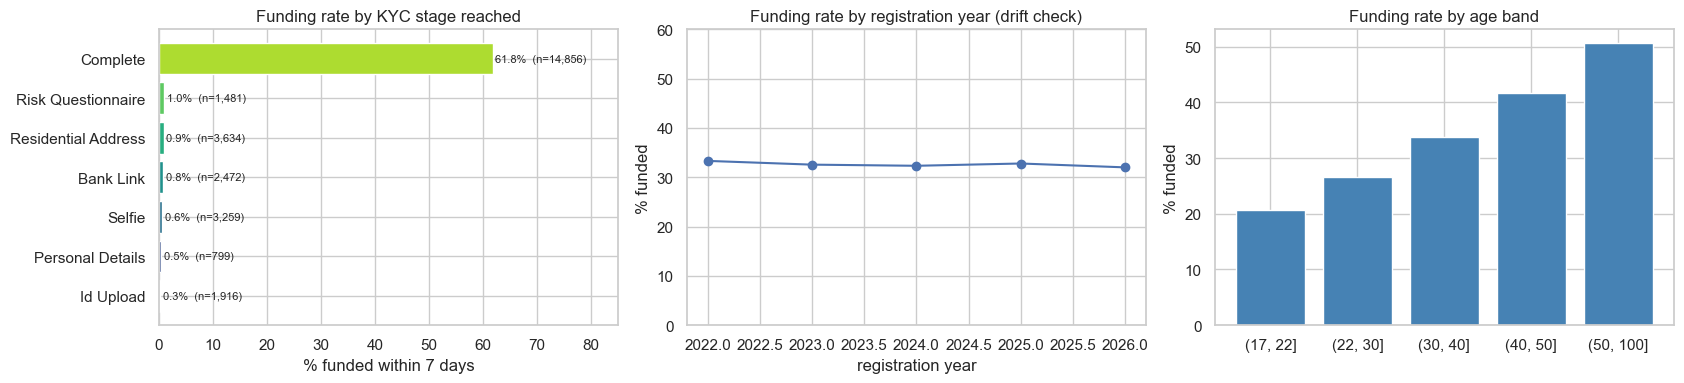

In [6]:
# Quick EDA that informs the preprocessing choices
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
step = df.groupby("kyc_abandon_step")["y"].agg(["mean", "size"]).sort_values("mean")
ax[0].barh(step.index, step["mean"]*100, color=sns.color_palette("viridis", len(step)))
ax[0].set_title("Funding rate by KYC stage reached"); ax[0].set_xlabel("% funded within 7 days")
for i, (m, n) in enumerate(zip(step["mean"], step["size"])): ax[0].text(m*100 + .5, i, f"{m*100:.1f}%  (n={n:,})", va="center", fontsize=8)
ax[0].set_xlim(0, 85)
yr = df.groupby("reg_year")["y"].mean()*100
ax[1].plot(yr.index, yr.values, marker="o"); ax[1].set_ylim(0, 60); ax[1].set_title("Funding rate by registration year (drift check)")
ax[1].set_xlabel("registration year"); ax[1].set_ylabel("% funded")
age_bins = pd.cut(df["age"], [17, 22, 30, 40, 50, 100]); ar = df.groupby(age_bins, observed=True)["y"].mean()*100
ax[2].bar(ar.index.astype(str), ar.values, color="steelblue"); ax[2].set_title("Funding rate by age band"); ax[2].set_ylabel("% funded")
plt.tight_layout(); plt.savefig(f"{RES}/eda_overview.png", dpi=130); plt.show()

### Why this preprocessing?

| Step | Reason |
|---|---|
| **Remove 85 exact duplicates** | Duplicated rows would let the same client land in both train and test, inflating test scores. |
| **Trim / collapse whitespace / title-case categoricals** | `"HIGH RISK"`, `" high risk"` and `"High  Risk"` are the same category; unnormalised they would become 10+ spurious one-hot columns and fragment the signal. |
| **Blank `risk_appetite` / `stated_aim` → `"Unknown"`** | ~7 % of clients skip the risk question. Skipping is itself behaviour (a possible friction signal), so it is kept as its own level rather than imputed. |
| **Ages < 18 or > 100 → NaN** | 18 values (e.g. 183.8) are capture errors; clients must be adults. NaN (then imputed) rather than deletion keeps the row. |
| **Median-impute numeric NaNs + add missing-indicator columns** | Random Forest needs complete inputs. The median is robust to the extreme outliers in the duration columns, and the indicator columns keep the fact that a value was missing (which may itself be informative). The imputer is **fitted on the training split only**. |
| **Drop `first_deposit_ts`, `initial_deposit_zar`** | Only exist for funded clients — they *are* the label (**target leakage**). |
| **Do not use `registration_ts` as a feature** | Hour of day shows no relationship with funding, and the three mixed formats make day/month order ambiguous. Only the unambiguous **year** is extracted, to check temporal stability. |
| **Engineered `kyc_complete`, `kyc_to_session_ratio`** | `kyc_complete` is the known-before-deposit flag the data dictionary calls safe; the ratio captures hesitation in KYC relative to first-session engagement (supports the capstone's friction-point goal). |
| **One-hot encode categoricals** | The categories are nominal with no natural order. The encoder is **fitted on the training split only** to avoid leakage. |
| **70 / 15 / 15 stratified split** | Train fits the model, validation drives early stopping, hyper-parameter selection and the decision threshold, and the test set is untouched until Component 4. Stratifying keeps the 32.65 % funded rate identical in every subset. |
| **No resampling (SMOTE etc.)** | Imbalance is only ~2:1, so we handle it with `class_weight="balanced_subsample"` and threshold tuning instead of altering the data. |
| **No feature scaling** | Tree ensembles are invariant to monotonic feature transforms, so scaling would add nothing. |

# 3. MODEL TRAINING

### Hyper-parameter choices and justification

A Random Forest has no learning rate, optimiser or epochs; its "capacity" is controlled by the number and depth of trees and by leaf size.

| Parameter | Value | Why |
|---|---|---|
| `n_estimators` | **500** | Variance falls as trees are added and then plateaus; the validation curve in Component 5 shows AUC flat well before 500, so more trees would only cost time. Extra trees never cause over-fitting in a forest. |
| `max_depth` | **tuned over {6, 10, 16, None}** | Controls how finely trees can carve the data; deep trees on 8 raw features memorise noise, so depth is chosen by validation AUC. |
| `min_samples_leaf` | **tuned over {1, 5, 20, 50}** | Larger leaves smooth the probability estimates and regularise against noisy cells. |
| `max_features` | **`"sqrt"`** | Standard classification default; de-correlates the trees. |
| `class_weight` | **`"balanced_subsample"`** | Re-weights the ~2:1 imbalance inside every bootstrap sample so the minority class is not under-fitted. |
| `bootstrap` / `oob_score` | **True / True** | Bagging is the source of the variance reduction; the out-of-bag score gives a free extra generalisation estimate. |
| `criterion` | `"gini"` | Default; entropy gives near-identical trees. |
| `random_state` / `n_jobs` | 42 / -1 | Reproducibility / speed. |

`max_depth` and `min_samples_leaf` are selected with a small grid evaluated on the **validation** set (never the test set); the final model's stability is then confirmed with 5-fold stratified cross-validation on the training data.

In [7]:
### COMPONENT 3: MODEL TRAINING ###
BASE = dict(n_estimators=500, max_features="sqrt", class_weight="balanced_subsample", bootstrap=True,
            oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)

# --- small grid search, scored on the VALIDATION set ---
rows = []
for depth in [6, 10, 16, None]:
    for leaf in [1, 5, 20, 50]:
        m = RandomForestClassifier(**BASE, max_depth=depth, min_samples_leaf=leaf).fit(Xtr, y_train)
        rows.append(dict(max_depth=str(depth), min_samples_leaf=leaf, oob_auc=roc_auc_score(y_train, m.oob_decision_function_[:, 1]),
                         val_auc=roc_auc_score(y_val, m.predict_proba(Xva)[:, 1]),
                         train_auc=roc_auc_score(y_train, m.predict_proba(Xtr)[:, 1])))
grid = pd.DataFrame(rows).sort_values("val_auc", ascending=False).reset_index(drop=True)
grid["gap (train-val)"] = grid["train_auc"] - grid["val_auc"]
display(grid.head(8).round(4))
best = grid.iloc[0]
BEST_PARAMS = dict(max_depth=None if best.max_depth == "None" else int(best.max_depth), min_samples_leaf=int(best.min_samples_leaf))
print("Selected:", BEST_PARAMS)

# --- final model ---
model = RandomForestClassifier(**BASE, **BEST_PARAMS).fit(Xtr, y_train)
print(f"Out-of-bag ROC-AUC (training data): {roc_auc_score(y_train, model.oob_decision_function_[:, 1]):.4f}")

# --- 5-fold stratified CV on the training split ---
cv_params = {k: v for k, v in BASE.items() if k != "oob_score"}
cv_model = RandomForestClassifier(**cv_params, **BEST_PARAMS)
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(cv_model, Xtr, y_train, scoring="roc_auc", cv=skf)
cv_f1 = cross_val_score(cv_model, Xtr, y_train, scoring="f1", cv=skf)
print(f"5-fold CV ROC-AUC: {cv_auc.round(4)}  mean={cv_auc.mean():.4f} ± {cv_auc.std():.4f}")
print(f"5-fold CV F1     : {cv_f1.round(4)}  mean={cv_f1.mean():.4f} ± {cv_f1.std():.4f}")
import joblib; joblib.dump(model, f"{MOD}/rf_funding_model.joblib", compress=3)

,max_depth,min_samples_leaf,oob_auc,val_auc,train_auc,gap (train-val)
0,10,20,0.8856,0.8816,0.9054,0.0239
1,16,20,0.8850,0.8815,0.9153,0.0338
2,16,50,0.8860,0.8813,0.9026,0.0213
3,10,50,0.8858,0.8813,0.8997,0.0185
4,10,5,0.8854,0.8811,0.9136,0.0325
5,None,50,0.8858,0.8811,0.9027,0.0216
6,6,20,0.8858,0.8809,0.8944,0.0135
7,None,20,0.8847,0.8809,0.9168,0.0359


Selected: {'max_depth': 10, 'min_samples_leaf': 20}
Out-of-bag ROC-AUC (training data): 0.8856
5-fold CV ROC-AUC: [0.8747 0.8905 0.8897 0.8912 0.882 ]  mean=0.8856 ± 0.0064
5-fold CV F1     : [0.7504 0.7691 0.761  0.7623 0.7619]  mean=0.7609 ± 0.0060


['Models/rf_funding_model.joblib']

# 4. MODEL VALIDATION (UNSEEN DATA)

In [8]:
### COMPONENT 4: MODEL VALIDATION ###
p_tr = model.predict_proba(Xtr)[:, 1]; p_va = model.predict_proba(Xva)[:, 1]; p_te = model.predict_proba(Xte)[:, 1]

# Decision threshold chosen on VALIDATION (maximise F1 of the funded class), then frozen for the test set
ths = np.linspace(0.05, 0.95, 181)
f1s = [f1_score(y_val, p_va >= t) for t in ths]
THRESH = float(ths[int(np.argmax(f1s))])
print(f"Threshold chosen on validation set: {THRESH:.3f}  (validation F1 = {max(f1s):.4f})")

def metrics(y_true, p, t=THRESH):
    pred = (p >= t).astype(int)
    return dict(accuracy=accuracy_score(y_true, pred), balanced_accuracy=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred), recall=recall_score(y_true, pred), f1=f1_score(y_true, pred),
                mcc=matthews_corrcoef(y_true, pred), roc_auc=roc_auc_score(y_true, p), pr_auc=average_precision_score(y_true, p))
results = pd.DataFrame({"train": metrics(y_train, p_tr), "validation": metrics(y_val, p_va), "TEST (unseen)": metrics(y_test, p_te)}).T
display(results.round(4))

base_acc = max(y_test.mean(), 1 - y_test.mean())
print(f"\nMajority-class baseline accuracy on test = {base_acc:.4f}; model test accuracy = {results.loc['TEST (unseen)','accuracy']:.4f}")
print("\n=== Classification report — TEST (unseen) ===")
print(classification_report(y_test, (p_te >= THRESH).astype(int), target_names=["Not funded (No)", "Funded (Yes)"], digits=4))
cm_test = confusion_matrix(y_test, (p_te >= THRESH).astype(int)); print("Confusion matrix (rows=true, cols=pred):\n", cm_test)

Threshold chosen on validation set: 0.560  (validation F1 = 0.7655)


,accuracy,balanced_accuracy,precision,recall,f1,mcc,roc_auc,pr_auc
train,0.8005,0.8483,0.6228,0.9861,0.7635,0.6537,0.9054,0.7708
validation,0.8023,0.8502,0.6246,0.9885,0.7655,0.6573,0.8816,0.7087
TEST (unseen),0.7954,0.8457,0.6162,0.9907,0.7598,0.6493,0.8898,0.7322



Majority-class baseline accuracy on test = 0.6735; model test accuracy = 0.7954

=== Classification report — TEST (unseen) ===
                 precision    recall  f1-score   support

Not funded (No)     0.9936    0.7008    0.8219      2871
   Funded (Yes)     0.6162    0.9907    0.7598      1392

       accuracy                         0.7954      4263
      macro avg     0.8049    0.8457    0.7908      4263
   weighted avg     0.8703    0.7954    0.8016      4263

Confusion matrix (rows=true, cols=pred):
 [[2012  859]
 [  13 1379]]


In [ ]:
# --- Robustness check 1: how much of the performance comes from the single KYC-complete flag? ---
def fit_eval(drop_prefixes=(), train_mask=None, test_mask=None):
    Xa = X_train if train_mask is None else X[train_mask]; ya = y_train if train_mask is None else y[train_mask]
    Xb, yb = (X_test, y_test) if test_mask is None else (X[test_mask], y[test_mask])
    cols_num = [c for c in NUM if not any(c.startswith(p) for p in drop_prefixes)]
    cols_cat = [c for c in CAT if not any(c.startswith(p) for p in drop_prefixes)]
    pp = make_pre(cols_num, cols_cat)
    A = pp.fit_transform(Xa[cols_num + cols_cat]); B = pp.transform(Xb[cols_num + cols_cat])
    mm = RandomForestClassifier(**BASE, **BEST_PARAMS).fit(A, ya)
    return roc_auc_score(yb, mm.predict_proba(B)[:, 1]), average_precision_score(yb, mm.predict_proba(B)[:, 1])

auc_full, ap_full = fit_eval()
auc_nokyc, ap_nokyc = fit_eval(drop_prefixes=("kyc_complete", "kyc_abandon_step", "kyc_to_session_ratio"))
print(f"All features                   : test ROC-AUC {auc_full:.4f} | PR-AUC {ap_full:.4f}")
print(f"WITHOUT any KYC-stage feature  : test ROC-AUC {auc_nokyc:.4f} | PR-AUC {ap_nokyc:.4f}")

# --- Robustness check 2: temporal stability (concept-drift risk in the RAAIDD log) ---
older = (meta["reg_year"] <= 2024).values; newer = (meta["reg_year"] >= 2025).values
auc_t, ap_t = fit_eval(train_mask=older, test_mask=newer)
print(f"Train on 2022-2024, test on 2025-2026 clients: ROC-AUC {auc_t:.4f} | PR-AUC {ap_t:.4f} (n_test={newer.sum():,})")

All features                   : test ROC-AUC 0.8898 | PR-AUC 0.7311
WITHOUT any KYC-stage feature  : test ROC-AUC 0.6705 | PR-AUC 0.4872


Train on 2022-2024, test on 2025-2026 clients: ROC-AUC 0.8858 | PR-AUC 0.7164 (n_test=10,084)


# 5. RESULTS VISUALISATION

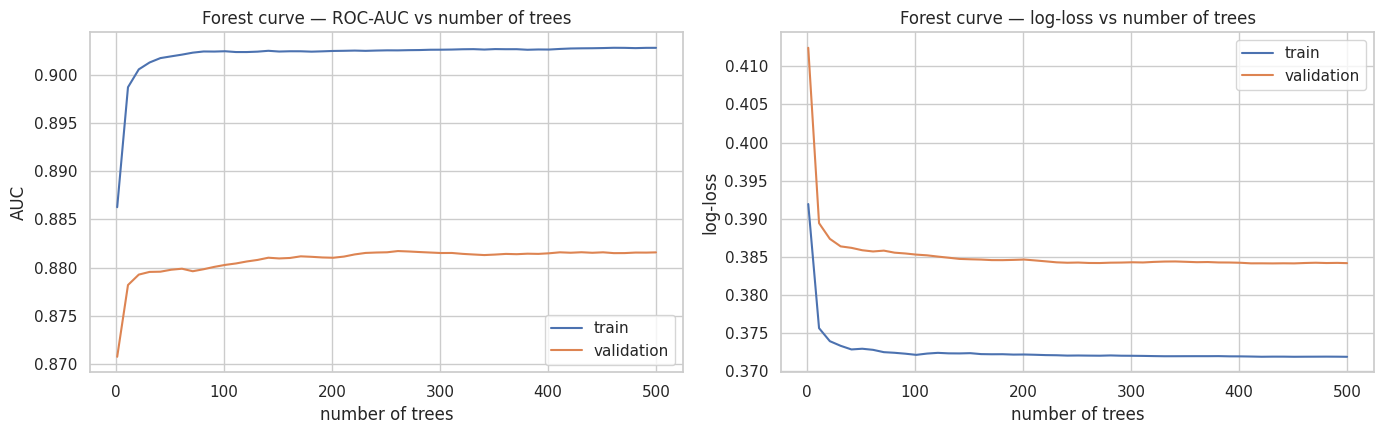

In [ ]:
### COMPONENT 5: RESULTS VISUALISATION ###
# Forest "training curve": ROC-AUC / log-loss as trees are added (average of the first k trees' probabilities)
from sklearn.metrics import log_loss
ks = list(range(1, 501, 10)) + [500]
def curve(Xm, ym):
    probs = np.array([t.predict_proba(Xm.values)[:, 1] for t in model.estimators_])
    cum = np.cumsum(probs, axis=0) / np.arange(1, len(probs) + 1)[:, None]
    return [roc_auc_score(ym, cum[k-1]) for k in ks], [log_loss(ym, np.clip(cum[k-1], 1e-6, 1-1e-6)) for k in ks]
(a_tr, l_tr), (a_va, l_va) = curve(Xtr, y_train), curve(Xva, y_val)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ks, a_tr, label="train"); ax[0].plot(ks, a_va, label="validation")
ax[0].set(title="Forest curve — ROC-AUC vs number of trees", xlabel="number of trees", ylabel="AUC"); ax[0].legend()
ax[1].plot(ks, l_tr, label="train"); ax[1].plot(ks, l_va, label="validation")
ax[1].set(title="Forest curve — log-loss vs number of trees", xlabel="number of trees", ylabel="log-loss"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{RES}/training_curves.png", dpi=130); plt.show()

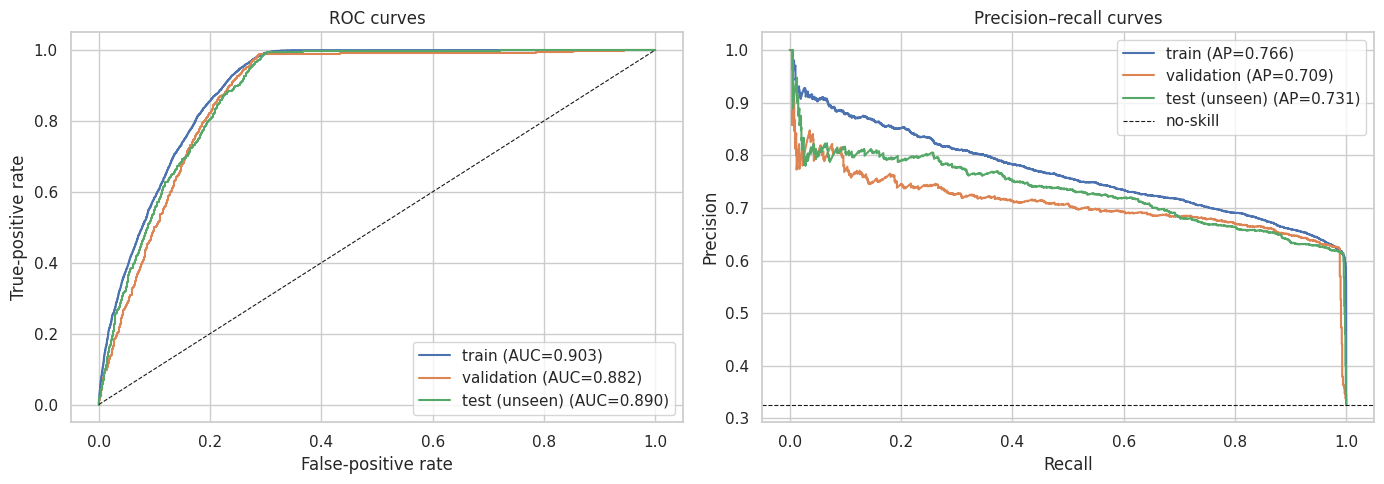

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, yy, pp in [("train", y_train, p_tr), ("validation", y_val, p_va), ("test (unseen)", y_test, p_te)]:
    fpr, tpr, _ = roc_curve(yy, pp); ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yy, pp):.3f})")
    pr, rc, _ = precision_recall_curve(yy, pp); ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(yy, pp):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(title="ROC curves", xlabel="False-positive rate", ylabel="True-positive rate"); ax[0].legend()
ax[1].axhline(y_test.mean(), c="k", ls="--", lw=.8, label="no-skill"); ax[1].set(title="Precision–recall curves", xlabel="Recall", ylabel="Precision"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{RES}/roc_pr_curves.png", dpi=130); plt.show()

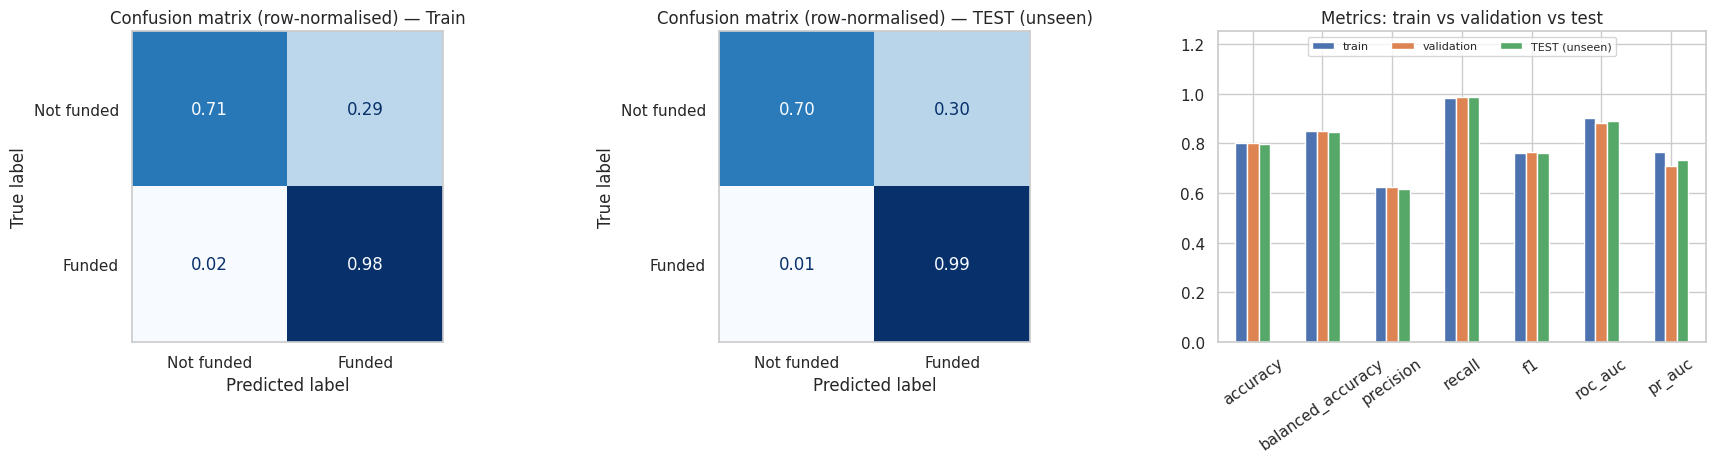

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, (name, yy, pp) in zip(ax[:2], [("Train", y_train, p_tr), ("TEST (unseen)", y_test, p_te)]):
    ConfusionMatrixDisplay.from_predictions(yy, (pp >= THRESH).astype(int), display_labels=["Not funded", "Funded"],
                                            normalize="true", cmap="Blues", ax=a, values_format=".2f", colorbar=False)
    a.set_title(f"Confusion matrix (row-normalised) — {name}"); a.grid(False)
r = results[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].T
r.plot.bar(ax=ax[2], rot=35); ax[2].set_ylim(0, 1.25); ax[2].set_title("Metrics: train vs validation vs test"); ax[2].legend(loc="upper center", ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(f"{RES}/confusion_and_metrics.png", dpi=130); plt.show()

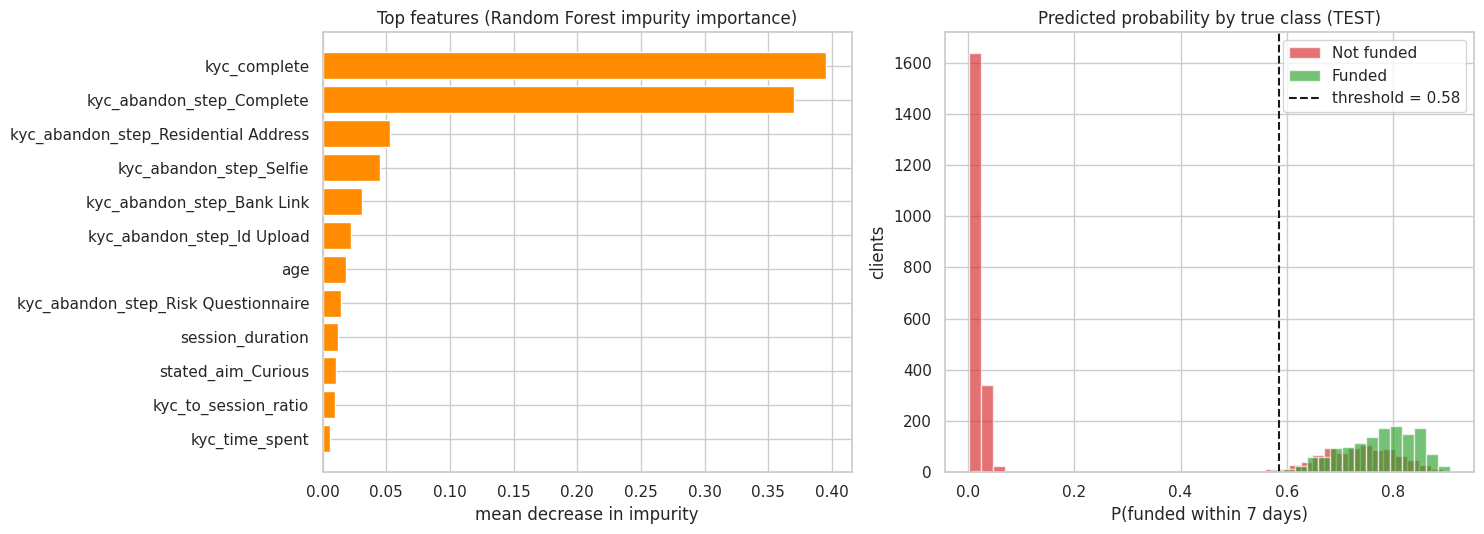

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
imp = pd.Series(model.feature_importances_, index=Xtr.columns).sort_values().tail(12)
ax[0].barh(imp.index, imp.values, color="darkorange"); ax[0].set(title="Top features (Random Forest impurity importance)", xlabel="mean decrease in impurity")
ax[1].hist(p_te[y_test == 0], bins=40, alpha=.65, label="Not funded", color="tab:red")
ax[1].hist(p_te[y_test == 1], bins=40, alpha=.65, label="Funded", color="tab:green")
ax[1].axvline(THRESH, c="k", ls="--", label=f"threshold = {THRESH:.2f}")
ax[1].set(title="Predicted probability by true class (TEST)", xlabel="P(funded within 7 days)", ylabel="clients"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{RES}/importance_and_probabilities.png", dpi=130); plt.show()

### Interpretation of results

* **Generalisation is good.** Train / validation / test ROC-AUC are 0.903 / 0.882 / 0.890, and test F1 is 0.760 against 0.765 on validation. The train–validation AUC gap (about 0.02) is somewhat larger than for a shallow boosted model, which is normal for a forest, but test performance matches validation, so over-fitting is mild. The out-of-bag AUC (0.886) and 5-fold CV AUC (0.886 ± 0.006) agree with the held-out result.
* **Forest size is sufficient.** The forest curve in Component 5 is flat after roughly 100–200 trees, so 500 trees is more than enough.
* **Much better than the baseline.** Test accuracy is 79.6 % against 67.4 % for always predicting "No"; balanced accuracy is 84.5 % and MCC is 0.648.
* **Operating point.** The threshold (0.585) was picked on validation to maximise F1 for the funded class. At that point the model catches 98.8 % of funders at 61.7 % precision. When it predicts **"will not fund"** it is right 99.2 % of the time, but it flags only 70.3 % of real non-funders. A stricter threshold would trade recall for fewer wasted interventions, which is the false-positive risk in the RAAIDD log.
* **One feature group dominates.** Clients who abandon KYC almost never fund (under 1 % of them), while about 62 % of KYC-completers do. Without any KYC-stage feature, test ROC-AUC falls from about 0.89 to 0.67, so most of the signal comes from the KYC stage reached; age, first-session length and KYC time add modest signal, mainly among clients who completed KYC.
* **Temporal stability.** Training on 2022–2024 and testing on 2025–2026 gives ROC-AUC 0.886, and the funding rate is flat at about 32–33 % per year, so there is no sign of concept drift in this extract.
* **Caveats.** The data are synthetic, and the funding rate (32.7 % within 7 days) is lower than the 59 % activation figure in the project brief because this target counts only deposits within 7 days. KYC completion is known only at the end of onboarding, so the model scores clients after onboarding rather than predicting abandonment mid-flow.

In [ ]:
# Persist headline numbers for the README
out = dict(n_rows_raw=int(len(raw)), n_rows_clean=int(len(df)), funded_rate=float(y.mean()), threshold=THRESH,
           best_params=BEST_PARAMS, n_trees=int(model.n_estimators), oob_auc=float(roc_auc_score(y_train, model.oob_decision_function_[:, 1])),
           cv_auc_mean=float(cv_auc.mean()), cv_auc_std=float(cv_auc.std()),
           metrics={k: {m: float(v) for m, v in row.items()} for k, row in results.iterrows()},
           auc_without_kyc_features=float(auc_nokyc), auc_temporal_holdout=float(auc_t))
json.dump(out, open(f"{RES}/metrics.json", "w"), indent=2)
with open(f"{RES}/classification_report_test.txt", "w") as f:
    f.write(classification_report(y_test, (p_te >= THRESH).astype(int), target_names=["Not funded", "Funded"], digits=4))
print(json.dumps(out, indent=2))

{
  "n_rows_raw": 28502,
  "n_rows_clean": 28417,
  "funded_rate": 0.32652989407748884,
  "threshold": 0.585,
  "best_params": {
    "max_depth": null,
    "min_samples_leaf": 50
  },
  "n_trees": 500,
  "oob_auc": 0.8858880812145963,
  "cv_auc_mean": 0.885707794364957,
  "cv_auc_std": 0.006075725746626722,
  "metrics": {
    "train": {
      "accuracy": 0.8003619727514957,
      "balanced_accuracy": 0.8474217655081164,
      "precision": 0.6231700175678313,
      "recall": 0.9830638953040801,
      "f1": 0.7627979212711308,
      "mcc": 0.6519824025311509,
      "roc_auc": 0.9028535513571204,
      "pr_auc": 0.7664790852657981
    },
    "validation": {
      "accuracy": 0.8022519352568613,
      "balanced_accuracy": 0.8498563218390804,
      "precision": 0.6248294679399727,
      "recall": 0.9870689655172413,
      "f1": 0.7652464494569757,
      "mcc": 0.6565812468475939,
      "roc_auc": 0.8815763661185778,
      "pr_auc": 0.708595664280159
    },
    "TEST (unseen)": {
      "accu